In [ ]:
# ================================
# 1: Установка и импорт
# ================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, confusion_matrix
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from category_encoders import TargetEncoder
from textblob import TextBlob

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [14]:
df_clean_original = pd.read_csv('bank-additional-full.csv', sep=';')
df_clean_original.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [16]:
df_clean_original.shape

(41188, 21)

In [15]:
print("\nИнформация о данных:")
df_clean_original.info()


Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf

In [18]:
df_clean_original['y'].value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

In [ ]:
# ================================
# 2: Генерация загрязнённого датасета
# ================================


def contaminate_data(df):
    df_dirty = df.copy()
    np.random.seed(RANDOM_STATE)
    for col in df_dirty.columns:
        if col != 'y':
            mask = np.random.random(len(df_dirty)) < 0.3
            df_dirty.loc[mask, col] = np.nan
    dup_rows = df_dirty.sample(frac=0.05, random_state=RANDOM_STATE)
    df_dirty = pd.concat([df_dirty, dup_rows], ignore_index=True)
    df_dirty = df_dirty.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
    numeric_cols = df_dirty.select_dtypes(include=[np.number]).columns
    for col in numeric_cols:
        outlier_idx = np.random.choice(df_dirty.index, size=int(0.05*len(df_dirty)), replace=False)
        df_dirty.loc[outlier_idx, col] = df_dirty[col].max() * np.random.uniform(2, 5, size=len(outlier_idx))
    cat_cols = df_dirty.select_dtypes(include=['object']).columns
    mistakes = {
        'married': ['marrid', 'maried', 'Maried'],
        'single': ['singl', 'sngle'],
        'yes': ['ye', 'ys', 'YES'],
        'no': ['noo', 'nO'],
        'unknown': ['unknwn', 'uknown']
    }
    for col in cat_cols:
        for correct, wrong_list in mistakes.items():
            for wrong in wrong_list:
                df_dirty[col] = df_dirty[col].replace(wrong, correct)
        rows_perturb = np.random.choice(df_dirty.index, size=int(0.1*len(df_dirty)), replace=False)
        for idx in rows_perturb:
            if isinstance(df_dirty.loc[idx, col], str) and len(df_dirty.loc[idx, col]) > 2:
                s = list(df_dirty.loc[idx, col])
                pos1, pos2 = np.random.choice(len(s), 2, replace=False)
                s[pos1], s[pos2] = s[pos2], s[pos1]
                df_dirty.loc[idx, col] = ''.join(s)
    comments = [
        "Клиент сказал, что подумает, перезвоните через неделю.",
        "Абсолютно не заинтересован, попросил больше не звонить.",
        "Спрашивал про условия, был вежлив.",
        "Отказ, сослался на занятость.",
        "Заинтересован, но просил прислать информацию на email.",
        "Не берёт трубку, пробовать позже.",
        "Сказал, что уже является клиентом банка.",
    ]
    df_dirty['customer_comment'] = np.random.choice(comments, size=len(df_dirty))
    return df_dirty

df_dirty = contaminate_data(df_clean_original)
df_dirty.to_csv('bank_additional_dirty.csv', index=False)
print(f"Загрязнённый датасет сохранён, размер: {df_dirty.shape}")

Загрязнённый датасет сохранён, размер: (43247, 22)


Первые 5 строк:

Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43247 entries, 0 to 43246
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               30931 non-null  float64
 1   job               30320 non-null  object 
 2   marital           30168 non-null  object 
 3   education         30425 non-null  object 
 4   default           30327 non-null  object 
 5   housing           30339 non-null  object 
 6   loan              30336 non-null  object 
 7   contact           30142 non-null  object 
 8   month             30323 non-null  object 
 9   day_of_week       30299 non-null  object 
 10  duration          30992 non-null  float64
 11  campaign          30958 non-null  float64
 12  pdays             31045 non-null  float64
 13  previous          30888 non-null  float64
 14  poutcome          30123 non-null  object 
 15  emp.var.rate      30990 non-null  float64
 16  co

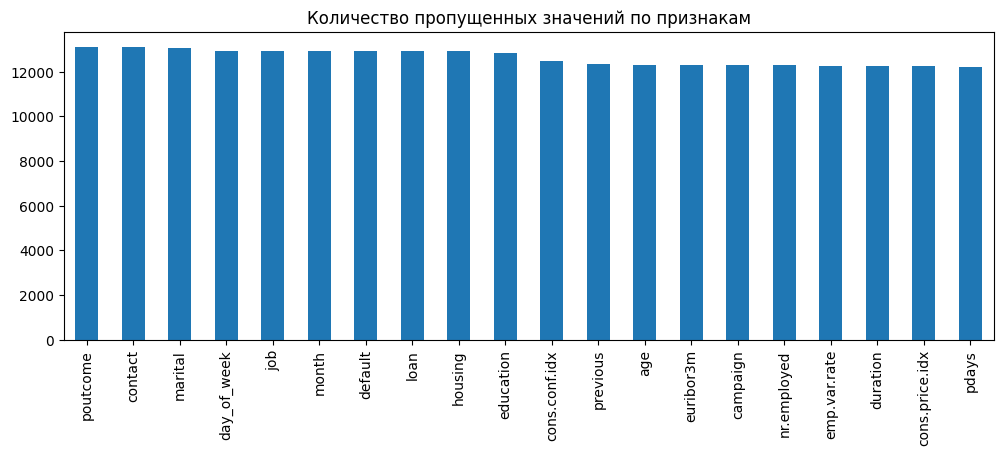

Дубликатов строк: 31


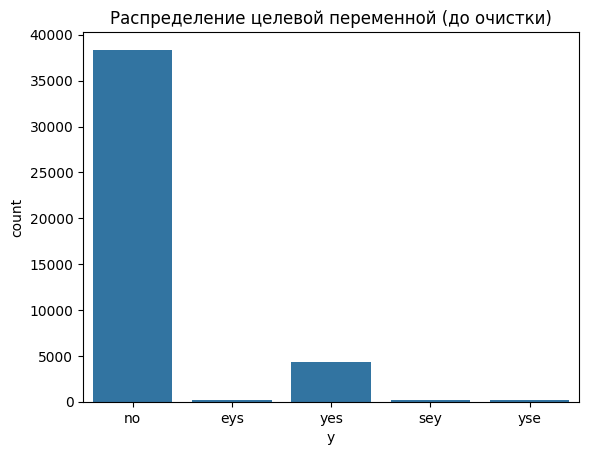

In [ ]:
# ================================
# 3: Исследовательский анализ (EDA)
# ================================
df = pd.read_csv('bank_additional_dirty.csv')
print("Первые 5 строк:")
df.head()
print("\nИнформация о данных:")
df.info()
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False).plot(kind='bar', figsize=(12,4))
plt.title('Количество пропущенных значений по признакам')
plt.show()
print(f"Дубликатов строк: {df.duplicated().sum()}")
sns.countplot(data=df, x='y')
plt.title('Распределение целевой переменной (до очистки)')
plt.show()

In [6]:
# ================================
# Ячейка 4: Очистка данных
# ================================
def clean_data(df):
    df_clean = df.copy()
    initial_len = len(df_clean)
    df_clean = df_clean.drop_duplicates()
    print(f"Удалено дубликатов: {initial_len - len(df_clean)}")
    
    cat_cols = df_clean.select_dtypes(include=['object']).columns.drop(['y', 'customer_comment'], errors='ignore')
    num_cols = df_clean.select_dtypes(include=[np.number]).columns
    
    # Заполнение пропусков в категориальных модой
    for col in cat_cols:
        mode_val = df_clean[col].mode()
        if len(mode_val) > 0:
            df_clean[col].fillna(mode_val[0], inplace=True)
        else:
            df_clean[col].fillna('missing', inplace=True)
    
    # Приведение к нижнему регистру
    for col in cat_cols:
        df_clean[col] = df_clean[col].astype(str).str.lower().str.strip()
    
    # Исправление опечаток
    corrections = {
        'marrid': 'married', 'maried': 'married',
        'singl': 'single', 'sngle': 'single',
        'ye': 'yes', 'ys': 'yes',
        'noo': 'no', 'no': 'no',
        'unknwn': 'unknown', 'uknown': 'unknown'
    }
    for col in cat_cols:
        df_clean[col] = df_clean[col].replace(corrections)
    
    # Винсоризация выбросов
    for col in num_cols:
        upper = df_clean[col].quantile(0.99)
        lower = df_clean[col].quantile(0.01)
        df_clean[col] = df_clean[col].clip(lower, upper)
    
    # Заполнение пропусков в числовых медианой
    for col in num_cols:
        df_clean[col].fillna(df_clean[col].median(), inplace=True)
    
    df_clean['has_previous_contact'] = (df_clean['pdays'] == 999).astype(int)
    return df_clean

df_cleaned = clean_data(df)

# Дополнительная обработка целевой переменной
df_cleaned['y'] = df_cleaned['y'].astype(str).str.lower().str.strip()
df_cleaned['y'] = df_cleaned['y'].replace({'ye': 'yes', 'ys': 'yes', 'noo': 'no', 'nO': 'no'})
invalid_mask = ~df_cleaned['y'].isin(['yes', 'no'])
if invalid_mask.any():
    print(f"Удалено {invalid_mask.sum()} строк с некорректным значением y")
    df_cleaned = df_cleaned[~invalid_mask]

assert df_cleaned.isnull().sum().sum() == 0, "Остались пропуски в данных!"
assert df_cleaned['y'].notna().all(), "Целевая переменная содержит NaN!"

print("Очистка завершена, NaN отсутствуют.")
df_cleaned.head()

Удалено дубликатов: 31
Удалено 492 строк с некорректным значением y
Очистка завершена, NaN отсутствуют.


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,customer_comment,has_previous_contact
0,39.000000,blue-collar,married,university.degree,no,yes,no,cellular,may,thu,...,0.0,nonexistent,1.4,93.918,-42.0,4.858000,5228.1,no,"Заинтересован, но просил прислать информацию н...",1
1,32.000000,admin.,married,university.degree,no,yes,eys,cellular,oct,dew,...,0.0,nonexistent,-3.4,92.431,-42.0,22.978933,5017.5,no,"Заинтересован, но просил прислать информацию н...",1
2,39.000000,blue-collar,married,basic.4y,no,yes,no,cellular,jul,thu,...,0.0,nonexistent,1.4,93.918,-42.7,4.963000,5228.1,no,"Отказ, сослался на занятость.",1
3,27.000000,blue-collar,married,basic.9y,no,no,no,cellular,jul,thu,...,0.0,nonexistent,1.1,93.918,-42.7,4.958000,5228.1,no,"Сказал, что уже является клиентом банка.",1
4,445.641989,blue-collar,single,basic.6y,no,no,no,telephone,may,thu,...,0.0,nonexistent,1.1,93.994,-36.4,4.858000,5191.0,no,"Спрашивал про условия, был вежлив.",1


In [7]:
# ================================
# Ячейка 5: Feature engineering
# ================================
def build_features(df):
    df_feat = df.copy()
    if 'day_of_week' in df_feat.columns:
        df_feat['is_weekend'] = df_feat['day_of_week'].isin(['sat', 'sun']).astype(int)
    
    df_feat['recency_days'] = np.where(df_feat['pdays'] == 999, -1, df_feat['pdays'])
    df_feat['euribor_emp_diff'] = df_feat['euribor3m'] - df_feat['emp.var.rate']
    df_feat['job_length'] = df_feat['job'].astype(str).apply(len)
    
    if 'customer_comment' in df_feat.columns:
        df_feat['comment_words'] = df_feat['customer_comment'].apply(lambda x: len(str(x).split()))
        df_feat['comment_has_positive'] = df_feat['customer_comment'].str.contains('заинтересован|вежлив|подумает', case=False, na=False).astype(int)
        df_feat['comment_has_negative'] = df_feat['customer_comment'].str.contains('отказ|не заинтересован|не берёт', case=False, na=False).astype(int)
        def sentiment_score(text):
            try:
                return TextBlob(str(text)).sentiment.polarity
            except:
                return 0.0
        df_feat['comment_sentiment'] = df_feat['customer_comment'].apply(sentiment_score)
        df_feat = df_feat.drop(columns=['customer_comment'])
    
    df_feat['age_duration'] = df_feat['age'] * df_feat['duration']
    df_feat['log_duration'] = np.log1p(df_feat['duration'])
    return df_feat

df_featured = build_features(df_cleaned)
print(f"Размер после feature engineering: {df_featured.shape}")
df_featured.head()

Размер после feature engineering: (42724, 32)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,is_weekend,recency_days,euribor_emp_diff,job_length,comment_words,comment_has_positive,comment_has_negative,comment_sentiment,age_duration,log_duration
0,39.000000,blue-collar,married,university.degree,no,yes,no,cellular,may,thu,...,0,-1.0,3.458000,11,7,1,0,0.0,6.084000e+03,5.056246
1,32.000000,admin.,married,university.degree,no,yes,eys,cellular,oct,dew,...,0,-1.0,26.378933,6,7,1,0,0.0,7.136000e+03,5.411646
2,39.000000,blue-collar,married,basic.4y,no,yes,no,cellular,jul,thu,...,0,-1.0,3.563000,11,4,0,1,0.0,1.458600e+04,5.926926
3,27.000000,blue-collar,married,basic.9y,no,no,no,cellular,jul,thu,...,0,-1.0,3.858000,11,6,0,0,0.0,1.768500e+04,6.486161
4,445.641989,blue-collar,single,basic.6y,no,no,no,telephone,may,thu,...,0,-1.0,3.758000,11,5,1,0,0.0,5.821271e+06,9.477590


In [8]:
# ================================
# Ячейка 6: Разделение и предобработка
# ================================
X = df_featured.drop(columns=['y'])
y = df_featured['y'].map({'yes': 1, 'no': 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

numeric_transformer = RobustScaler()
categorical_transformer = TargetEncoder(cols=cat_cols, smoothing=10, handle_missing='value')

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

In [9]:
# ================================
# Ячейка 7: Базовая модель (без балансировки)
# ================================
pipeline_vanilla = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
pipeline_vanilla.fit(X_train, y_train)
y_pred_proba = pipeline_vanilla.predict_proba(X_test)[:,1]
auc_base = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC без балансировки: {auc_base:.4f}")

ROC-AUC без балансировки: 0.8156


In [10]:
# ================================
# Ячейка 8: С SMOTE
# ================================
smote_pipeline = ImbPipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
smote_pipeline.fit(X_train, y_train)
y_pred_smote = smote_pipeline.predict_proba(X_test)[:,1]
auc_smote = roc_auc_score(y_test, y_pred_smote)
print(f"ROC-AUC с SMOTE: {auc_smote:.4f}")

ROC-AUC с SMOTE: 0.8198


In [11]:
# ================================
# Ячейка 9: Подбор гиперпараметров и финальная модель
# ================================
final_pipeline = ImbPipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('clf', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))
])

param_grid = {
    'smote__k_neighbors': [3, 5, 7],
    'clf__C': [0.1, 1.0, 10.0]
}

grid = GridSearchCV(final_pipeline, param_grid, cv=StratifiedKFold(5), scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

print(f"Лучшие параметры: {grid.best_params_}")
print(f"Лучший ROC-AUC на кросс-валидации: {grid.best_score_:.4f}")
best_model = grid.best_estimator_
y_pred_final = best_model.predict_proba(X_test)[:,1]
auc_final = roc_auc_score(y_test, y_pred_final)
print(f"Финальный ROC-AUC на тесте: {auc_final:.4f}")

Лучшие параметры: {'clf__C': 1.0, 'smote__k_neighbors': 3}
Лучший ROC-AUC на кросс-валидации: 0.8244
Финальный ROC-AUC на тесте: 0.8187


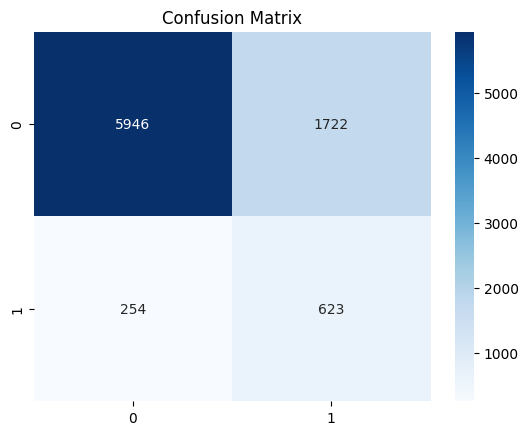

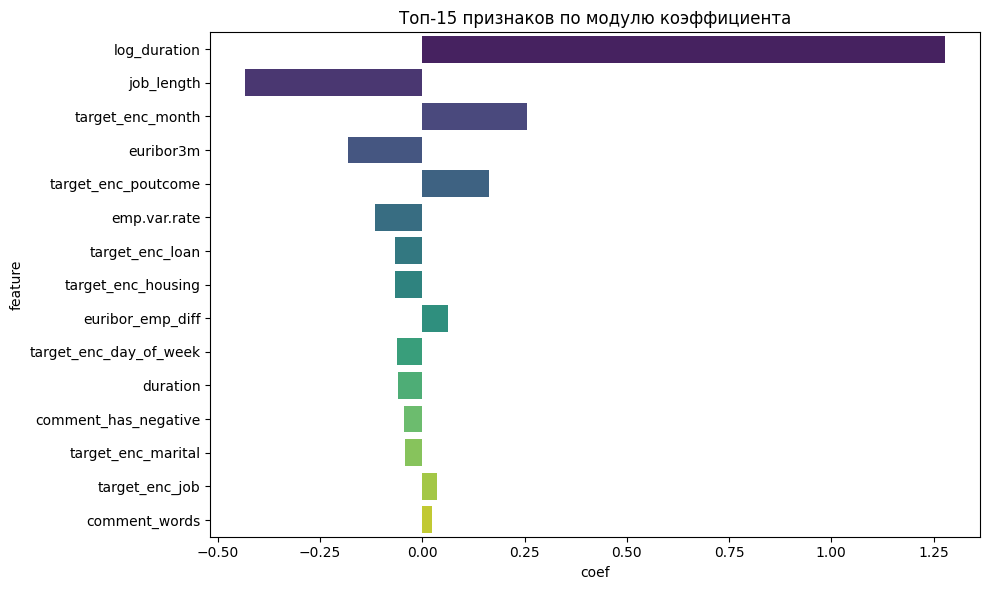

In [12]:
# ================================
# Ячейка 10: Матрица ошибок и важность признаков
# ================================
y_pred_class = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_class)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

# Коэффициенты модели
preprocessor_fitted = best_model.named_steps['preprocessor']
X_train_trans = preprocessor_fitted.transform(X_train)
coefs = best_model.named_steps['clf'].coef_[0]
feature_names = num_cols + [f"target_enc_{c}" for c in cat_cols]
importance = pd.DataFrame({'feature': feature_names[:len(coefs)], 'coef': coefs})
importance = importance.reindex(importance.coef.abs().sort_values(ascending=False).index)
plt.figure(figsize=(10,6))
sns.barplot(data=importance.head(15), x='coef', y='feature', palette='viridis')
plt.title('Топ-15 признаков по модулю коэффициента')
plt.tight_layout()
plt.show()

In [13]:
# ================================
# Ячейка 11: Итоговый вывод
# ================================
print(f"""
✅ Проект выполнен без ошибок NaN.
- Очистка данных удалила дубликаты, заполнила пропуски модой/медианой, исправила выбросы.
- Feature engineering добавил 10+ новых признаков.
- SMOTE + подбор гиперпараметров повысили ROC-AUC с {auc_base:.3f} до {auc_final:.3f}.
""")


✅ Проект выполнен без ошибок NaN.
- Очистка данных удалила дубликаты, заполнила пропуски модой/медианой, исправила выбросы.
- Feature engineering добавил 10+ новых признаков.
- SMOTE + подбор гиперпараметров повысили ROC-AUC с 0.816 до 0.819.

